### Klasifikacija rezencija mobilnih aplikacija pomocu **WORD EMBEDDINGS**

Ova sveska prikazuje primer klasifikacije teksta koriscenjem unapred istreniranog modela za predstavljanje reci pomocu vektora (**word embeddings**), pod nazivom [GloVe](https://nlp.stanford.edu/projects/glove/) . Ovaj model se koristi za pretvaranje tekstualnih podataka u numericke vektore koji se zatim prosledjuju algoritmima za klasifikaciju.

Skup podataka i zadatak klasifikacije je isti kao u prethodne dve nedelje.

#### PREUZIMANJE JEZICKIH MODELA
Do sada smo koristili najmanji spaCy model za engleski jezik (`en_core_web_sm`), koji sadrzi recnik i omogucava analizu sintakse i prepoznavanje imenovanih entiteta, ali ne sadrzi vektorske reprezentacije reci.

Da bismo koristili ugradjeni spaCy model za vektore reci, potrebno je da instaliramo veci jezicki model, odnosno `en_core_web_md` ili `en_core_web_lg`.

`python -m spacy download en_core_web_md`

`python -m spacy download en_core_web_lg`

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import RobustScaler
from sklearn.compose import ColumnTransformer

# moduli za pipeline i disbalans
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

from sklearn import metrics
from sklearn.metrics import ConfusionMatrixDisplay

# moduli za klasifikacione algoritme
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

import spacy
from pathlib import Path

In [2]:
RAND_STATE = 1

SPACY_MODEL = "en_core_web_md"

#### *Ucitavanje dataset-a, kreiranje izlazne varijable, izbor prediktora i podela podataka na train i test je isto kao prethodne dve nedelje*

In [3]:
data = pd.read_csv(Path.cwd() / 'data' / 'mobile_apps_reviews.csv')

data.head()

,id,app,version,rating,date,device,user,review,category
0,1,com.androtiyas.dragonvirtual,1.08,5,1387756426967,?,Alexis Gonzalez,cute!!!! the game is just to cute!!!! :3,OTHER
1,2,com.androtiyas.dragonvirtual,1.1,4,1390090741168,Galaxy Precedent,A Google User,? well its ok but not bad nor is it great,OTHER
2,3,com.androtiyas.dragonvirtual,?,1,1387746296815,Toshiba AT100,Reyna We,? have no idea how to feed dragon and boooorrr...,OTHER
3,4,com.androtiyas.dragonvirtual,1.06,2,1386518193950,?,mariah harris,when i play games it reboots about every third...,BUG
4,5,com.androtiyas.dragonvirtual,1.06,5,1386915595583,?,Wren Brown,love my dragon have fun! yahoooey! godbless,OTHER


In [4]:
def category_to_cls(cat):
    if cat == 'OTHER': return cat
    return "FUNCTIONAL" if cat in ['BUG', 'FEATURE'] else 'NON-FUNCTIONAL'


data['cls'] = data.category.apply(category_to_cls)
data.cls.value_counts(normalize=True)

cls
OTHER             0.501667
FUNCTIONAL        0.365667
NON-FUNCTIONAL    0.132667
Name: proportion, dtype: float64

In [5]:
data['review_len'] = data.review.apply(len)

X = data[['review', 'review_len', 'rating']]
y = data['cls']

y_encodings, y_levels = pd.factorize(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encodings, test_size=0.2, random_state=RAND_STATE, stratify=y
)

### KORISCENJE VEKTORA RECI (*WORD EMBEDDINGS*) ZA PREDSTAVLJANJE DOKUMENATA

Word embeddings predstavljaju nacin modelovanja teksta u kojem se svaka rec predstavlja visedimenzionalnim numerickim vektorom. Cilj je da taj vektor obuhvati sto vise informacija o znacenju reci (semantici), tako da reci slicnog znacenja imaju slicne vektorske reprezentacije.

Osnovna ideja: *„You shall know a word by the company it keeps.“* — Znacenje reci mozemo zakljuciti na osnovu reci koje se cesto pojavljuju u njenom okruzenju.

Medjutim, da bismo izvrsili klasifikaciju, potrebno je da numericki predstavimo citave recenzije (dokumente), a ne samo pojedinacne reci. Zato svaku recenziju predstavljamo jednim vektorom koji se dobija na osnovu vektora svih reci koje se u njoj pojavljuju.

Postoji vise nacina za to, a u ovom primeru koristi se jednostavna metoda: **racunanje proseka vektora svih reci u recenziji**.

To znaci da se za svaku dimenziju posebno sabiraju vrednosti te dimenzije iz vektora svih reci, a zatim se zbir deli brojem reci. Na primer, ako recenzija sadrzi tri reci ciji su vektori `[2, 4]`, `[4, 1]` i `[6, 7]`, prosecan vektor recenzije bice `[4, 4]`:

- Prva dimenzija: (2 + 4 + 6) / 3 = 4
- Druga dimenzija: (4 + 1 + 7) / 3 = 4

U nasem primeru, posto **GloVe** vektori imaju 300 dimenzija, racuna se prosek za svaku od tih 300 dimenzija i dobija se **jedan vektor od 300 brojeva za celu recenziju**.

Iako je ova metoda jednostavna, cesto daje dobre rezultate za kratke tekstove, kao sto su recenzije koje koristimo u ovom primeru. Nedostatak je sto se gubi informacija o redosledu reci, a prosecavanje moze da umanji uticaj pojedinih vaznih reci.

#### ISTRAZIVANJE GloVe

In [6]:
spacy_model = spacy.load(SPACY_MODEL, disable=['parser', 'ner'])

# disablujemo 2 komponente iz pipeline jer ih ne koristimo a i ubrzavamo sam pipeline, cross validaciju itd (nije neophodno)
# parser - analizira gramaticku strukturu recenice i odnose izmedju reci
# ner (Named Entity Recognition) - prepoznaje imenovane entitete u tekstu
# moze se primeniti i na prethodne casove

Ucitani NLP pipeline sadrci:
- Srednji model (`en_core_web_md`) – oko 20.000 jedinstvenih vektora za 685.000 razlicitih reči.
- Veliki model (`en_core_web_lg`) – oko 343.000 jedinstvenih vektora za 685.000 razlicitih reci.

U oba modela svaka rec predstavljena je vektorom od 300 dimenzija.

Broj razlicitih reci veci je od broja jedinstvenih vektora zato sto spaCy, radi smanjenja velicine modela, nekim srodnim recima dodeljuje isti vektor. Na primer, reci *kid*, *kids*, *child* i *children* mogu biti predstavljene istim vektorom.

In [7]:
# za svaku rec mozemo da pristupimo njegovom vektoru reci
world_vec = spacy_model('world').vector

print(f"Vectors dimension: {len(world_vec)}")

print('World: ', world_vec)
# sve je razlicito od 0 - nema sparsnih matrica, vec je dense

Vectors dimension: 300
World:  [-6.2752e-01  9.6647e-02  5.8525e-02 -4.1364e-02  8.2091e-03  1.2230e-01
 -3.7158e-01  1.1244e+00 -1.0964e-01  2.6778e+00  4.9412e-01 -3.1716e-01
 -7.4560e-02  3.4692e-01 -6.0170e-02  1.4428e-01 -4.0906e-01  3.7426e-01
 -1.8449e-01  1.6487e-01 -5.5287e-01 -1.4136e-01  2.9449e-01  4.7711e-01
  6.8386e-01 -4.7221e-02  7.1285e-01  3.0253e-01 -4.0780e-01  7.1487e-01
 -4.2733e-01  9.5346e-02 -4.8627e-01  1.4888e-01  4.4621e-01 -1.5371e-01
 -1.9430e-01 -1.4995e-01  2.8414e-02  5.7656e-01  1.2100e-02  1.5328e-04
 -7.4318e-02  4.7869e-01  3.0866e-02 -7.0779e-01 -7.7787e-02  5.5496e-01
 -2.1231e-01 -2.1367e-01  2.2433e-01 -1.6196e-01 -1.4790e-01 -1.7868e-01
  3.0867e-01 -1.4638e-01 -8.8241e-02 -4.4340e-02  2.9901e-01 -4.9765e-01
 -1.8245e-01 -3.5274e-01  9.0349e-02 -1.0826e+00 -1.7650e-01 -3.2504e-01
 -5.2780e-01 -3.9316e-01 -4.3747e-01 -3.0031e-01  9.5930e-02 -4.8797e-02
 -2.6289e-02 -2.2738e-01 -1.4851e-02  2.5013e-01 -3.0001e-01 -1.9170e-01
  4.4040e-01  1.9953

#### SLICNOST RECI (*WORD SIMILARITY*)

Kada su reci predstavljene numerickim vektorima, mozemo koristiti linearnu algebru i modele vektorskog prostora za analizu odnosa izmedju reci.

Slicnost reci određujemo pomocu **kosinusne slicnosti (*cosine similarity*)**, koja poredi vektorske reprezentacije dve reci i meri koliko su one slicne po smeru.

Kosinusna slicnost je cesto koriscena mera semanticke slicnosti reci. Njena vrednost krece se od -1 do 1, mada se u uobicajenim primenama nad nenegativnim vrednostima tumaci u opsegu od 0 do 1, gde:
- **0** oznacava odsustvo slicnosti;
- **1** oznacava maksimalnu slicnost, odnosno isti smer vektora.

U biblioteci spaCy kosinusna sličnost implementirana je kroz metodu `similarity()`.

In [8]:
dog = spacy_model('dog')
cat = spacy_model('cat')
computer = spacy_model('computer')
software = spacy_model('software')

print(f"Similarity of dog and cat: {dog.similarity(cat)}")
print(f"Similarity of dog and computer: {dog.similarity(computer)}")
print(f"Similarity of computer and software: {computer.similarity(software)}")

Similarity of dog and cat: 1.0000001192092896
Similarity of dog and computer: 0.07917961478233337
Similarity of computer and software: 0.9999999403953552


Vektore reci sa 300 dimenzija mozemo svesti na 2D pomocu algoritma za smanjenje dimenzionalnosti **t-SNE**, kako bismo mogli vizuelno da prikazemo odnose izmedju reci; interaktivna vizualizacija dostupna je na [TensorFlow Projector stranici](https://projector.tensorflow.org/).

### KREIRANJE CUSTOM KLASE TRANSFORMATORA

Kreiracemo klasu `ReviewVectorizer`, koja transformise svaku recenziju u vektorsku reprezentaciju, kao sto je prethodno opisano, koristeci unapred istrenirani GloVe model integrisan u spaCy NLP pipeline.

Pre ove transformacije, tekst se obradjuje tako da se izdvoje reci koje nose znacenje, odnosno uklone reci koje nisu znacajne za predstavljanje sadrzaja recenzije. Na taj nacin se za kreiranje vektorske reprezentacije koriste samo najvaznije reci.

Klasa `ReviewVectorizer` nasledjuje klase `BaseEstimator` i `TransformerMixin` iz biblioteke scikit-learn. To je potrebno kako bi nas prilagodjeni transformator bio kompatibilan sa scikit-learn alatima, kao sto su `GridSearchCV` i `Pipeline`.

- `TransformerMixin` omogucava da se nasa klasa ponasa kao scikit-learn transformator i da se ukljuci u `Pipeline`.
- `BaseEstimator` omogucava koriscenje metoda `get_params()` i `set_params()`, pomocu kojih možemo da pristupamo parametrima transformatora i menjamo ih, ukljucujuci njihovo podesavanje tokom pretrage najboljih hiperparametara.

Prilikom kreiranja prilagodjenog transformatora nasledjivanjem ovih klasa, potrebno je implementirati sledece metode:

**1. `__init__(self, *args, **kwargs)`** - konstruktor

**2. `fit(self, X, y=None)`** -  racuna neke statistike, to nemamo ovde

**3. `transform(self, X)`** - vraca transformisane podatke

In [9]:
class ReviewVectorizer(BaseEstimator, TransformerMixin):

    def __init__(self, spacy_pipeline, vector_dim=300):
        self.spacy_pipeline = spacy_pipeline
        self.vector_dim = vector_dim

    def spacy_tokenizer(self, doc):
        tokens = self.spacy_pipeline(doc)
        tokens = [token for token in tokens
                  if ((not token.is_punct) and
                      (not token.like_num) and
                      (not token.like_url) and
                      (not token.is_space) and
                      (not token.is_stop))]
        words = [token.lemma_.lower() for token in tokens]
        return words

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        # kreira se nula matrica - broj redova je broj dokumenata, broj kolona je dimenzija vektora
        X_transformed = np.zeros((len(X), self.vector_dim))

        for i, text in enumerate(X):
            words = self.spacy_tokenizer(text)
            X_transformed[i] = self.spacy_pipeline(" ".join(words)).vector

        return X_transformed

### TRENIRANJE KLASIFIKACIONOG MODELA

Koristimo klasu `ReviewVectorizer` da transformisemo recenzije u vektore pomocu *word embeddings*.

Koristimo `RobustScaler` da promenimo skalu dve dodatne numericke karakteristike tako da sve karakteristike imaju priblizno uporediv opseg vrednosti.

In [10]:
vectorizer = ReviewVectorizer(spacy_pipeline=spacy_model)

scaler = RobustScaler()

column_transformer = ColumnTransformer(
    transformers=[
        ('embeddings', vectorizer, 'review'),
        ('scaler', scaler, ['review_len', 'rating'])
    ]
)

Koristicemo **Logisticku regresiju (*Logistic Regression*)** kao klasifikator, jer su klasifikatori zasnovani na linearnim granicama odlucivanja pogodni za vektorski prostor koji formiraju gusti vektori (*embedding vectors*).

Takodje koristimo **SMOTE metodu** za ponovno uzorkovanje (*resampling*) kako bismo resili problem neuravnotezenog skupa podataka (*imbalanced dataset*). Podsetimo se da tri kategorije recenzija, odnosno klase, nisu podjednako zastupljene.

**SMOTE** je skracenica od *Synthetic Minority Oversampling Technique* i predstavlja tehniku za povecavanje broja primera u manjinskoj klasi, cime se postize uravnotezenija raspodela klasa. To se radi generisanjem novih, sintetickih primera na osnovu postojecih primera te klase.


Na kraju, vazno je napomenuti da koristimo `Pipeline` iz modula `imblearn.pipeline`, a ne iz `sklearn.pipeline`, kao u prethodnim vezbama. Bitna razlika je ta sto se balansiranje (SMOTE) radi samo na trening setu. Kod `sklear.pipeline` ne postoji opcija da se balansiranje preskoci na test setu, dok `imblearn.pipeline` automatski preskace balansiranje na test setu.

In [11]:
lr_classifier = LogisticRegression(random_state=RAND_STATE, max_iter=2000)

smote = SMOTE(random_state=RAND_STATE)

lr_pipe = Pipeline(
    steps=[
        ('transformator', column_transformer),
        ('resampling', smote),
        ('classifier', lr_classifier)
    ],
    verbose=True
)

lr_pipe.fit(X_train, y_train)

[Pipeline] ..... (step 1 of 3) Processing transformator, total=  20.9s
[Pipeline] ........ (step 2 of 3) Processing resampling, total=   2.9s
[Pipeline] ........ (step 3 of 3) Processing classifier, total=   0.5s


,steps,"[('transformator', ...), ('resampling', ...), ...]"
,transform_input,None
,memory,None
,verbose,True
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('embeddings', ...), ('scaler', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for 

#### EVALUACIJA PIPELINE-a

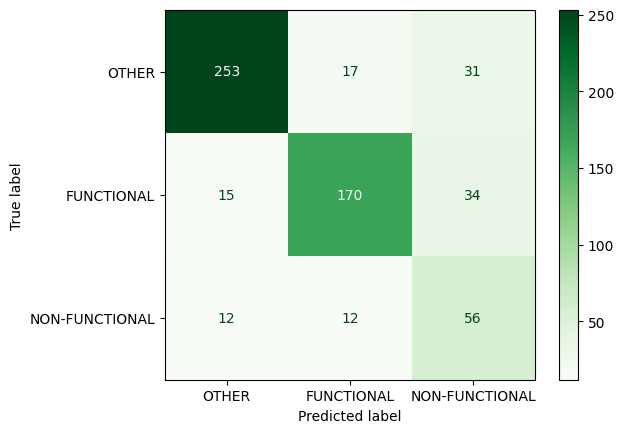

In [12]:
ConfusionMatrixDisplay.from_estimator(
    lr_pipe,
    X_test,
    y_test,
    display_labels=y_levels,
    cmap='Greens'
)

In [13]:
lr_predictions = lr_pipe.predict(X_test)

print(metrics.classification_report(y_true=y_test, y_pred=lr_predictions))

              precision    recall  f1-score   support

           0       0.90      0.84      0.87       301
           1       0.85      0.78      0.81       219
           2       0.46      0.70      0.56        80

    accuracy                           0.80       600
   macro avg       0.74      0.77      0.75       600
weighted avg       0.83      0.80      0.81       600



In [14]:
bas_lr = metrics.balanced_accuracy_score(y_test, lr_predictions)
print(f"Balanced accuracy: {bas_lr:0.4f}")

Balanced accuracy: 0.7723


# SVM KLASIFIKATOR

Sad cemo koristiti **SVM (Support Vector Machine)**, odnosno metodu potpornih vektora, kao klasifikator.

SVM se uspesno koristi u klasifikaciji teksta jer dobro obradjuje podatke sa velikim brojem dimenzija, kao sto su vektorske reprezentacije reci (*embeddings*), a dobro funkcionise i sa relativno malim skupovima podataka.

Koristicemo najjednostavniju verziju SVM-a — **SVM sa linearnim jezgrom (*linear kernel*)**, pomocu klase `SVC` iz biblioteke scikit-learn i parametra `kernel='linear'`.

#### 1. Hiperravan, margina i potporni vektori

Kada su podaci linearno razdvojivi, SVM trazi **optimalnu hiperravan** (*optimal hyperplane*), odnosno granicu koja razdvaja klase tako da margina bude maksimalna.

- **Hiperravan (*hyperplane*)** – granica koja razdvaja klase. U dve dimenzije predstavlja pravu liniju, u tri dimenzije ravan, a u prostoru sa vise dimenzija hiperravan.
- **Margina (*margin*)** – rastojanje izmedju granice razdvajanja i najblizih primera razlicitih klasa. SVM nastoji da pronadje granicu sa sto sirom marginom.
- **Potporni vektori (*support vectors*)** – primeri koji se nalaze najblize granici i koji imaju kljucnu ulogu u odredjivanju njenog polozaja.

#### 2. Parametar `C`

Parametar `C` kontrolise koliko model kaznjava greske na trening skupu i utice na kompromis izmedju sirine margine i pogresno klasifikovanih primera.

- **Veliko `C`** – model stroze kaznjava greske na trening skupu, pa pokusava da ih izbegne cak i ako margina postane uza. Ako je `C` previse veliki, postoji rizik od *overfittinga*.
- **Malo `C`** – model vise tolerise greske na trening skupu i moze da pronadje siru marginu. Ako je `C` previse mali, postoji rizik od *underfittinga*.

- **Overfitting** – model se previse prilagodjava trening podacima i slabije generalizuje na nove podatke.
- **Underfitting** – model nije dovoljno dobro naucio obrasce u podacima.

#### 3. Viseklasna klasifikacija

SVM je prvobitno namenjen klasifikaciji izmedju dve klase. Kada imamo vise klasa koriste se strategije za viseklasnu klasifikaciju.

**One-vs-Rest (OvR)**

Za svaku klasu pravi se po jedan klasifikator koji tu klasu razlikuje od svih ostalih klasa zajedno. Prednost je jednostavniji postupak, dok je nedostatak to sto klase mogu biti nebalansirane.

**One-vs-One (OvO)**

Pravi se poseban klasifikator za svaki par klasa. OvO moze biti praktican jer svaki klasifikator poredi samo dve klase, ali i dalje moze biti osetljiv na neuravnotezenost unutar pojedinacnih parova klasa.

**Napomena:** scikit-learn implementacija `SVC` podrazumevano koristi One-vs-One pristup za viseklasnu klasifikaciju.

#### 4. Kernel funkcije (*Kernel functions*)

Ako podaci nisu linearno razdvojivi, transformisu se u visedimenzionalni prostor gde jesu linearno separabilni. Ovo radi kernel f-ja. Najcesce koriscene: `poly`, `rbf`, `sigmoid`

In [15]:
svm_classifier = SVC(
    C=1,  # default
    kernel='linear',
    random_state=RAND_STATE
)

svm_pipe = Pipeline(
    steps=[
        ('transformator', column_transformer),
        ('resampling', smote),
        ('classifier', svm_classifier)
    ],
    verbose=True
)

svm_pipe.fit(X_train, y_train)

[Pipeline] ..... (step 1 of 3) Processing transformator, total=  21.1s
[Pipeline] ........ (step 2 of 3) Processing resampling, total=   0.1s
[Pipeline] ........ (step 3 of 3) Processing classifier, total=   0.9s


,steps,"[('transformator', ...), ('resampling', ...), ...]"
,transform_input,None
,memory,None
,verbose,True
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('embeddings', ...), ('scaler', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for 

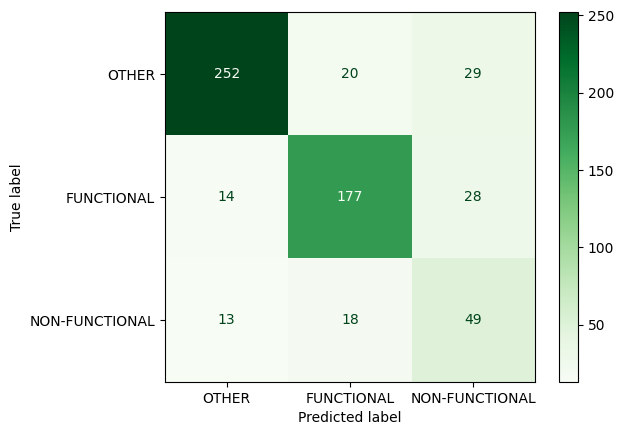

In [16]:
ConfusionMatrixDisplay.from_estimator(
    svm_pipe,
    X_test,
    y_test,
    display_labels=y_levels,
    cmap='Greens'
)

In [17]:
svm_predictions = svm_pipe.predict(X_test)

print(metrics.classification_report(y_test, svm_predictions, target_names=y_levels))

                precision    recall  f1-score   support

         OTHER       0.90      0.84      0.87       301
    FUNCTIONAL       0.82      0.81      0.82       219
NON-FUNCTIONAL       0.46      0.61      0.53        80

      accuracy                           0.80       600
     macro avg       0.73      0.75      0.74       600
  weighted avg       0.82      0.80      0.80       600



In [18]:
bacc_svm = metrics.balanced_accuracy_score(y_test, svm_predictions)
print(f"Balanced accuracy: {bacc_svm:0.4f}")

Balanced accuracy: 0.7526


### POBOLJSANJE *SVM* MODELA POMOCU HIPERPARAMETARA

In [19]:
### POTREBNO VREME - 15ak !!!

param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100]
}
grid_search = GridSearchCV(estimator=svm_pipe,
                           param_grid=param_grid,
                           scoring='f1_macro',
                           verbose=2)
# grid_search.set_params(classifier__max_iter=5000) - u slucaju da tunning predugo traje, default vrednost nije ogranicena

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 5 candidates, totalling 25 fits
[Pipeline] ..... (step 1 of 3) Processing transformator, total=  18.8s
[Pipeline] ........ (step 2 of 3) Processing resampling, total=   0.0s
[Pipeline] ........ (step 3 of 3) Processing classifier, total=   0.8s
[CV] END .................................classifier__C=0.01; total time=  23.1s
[Pipeline] ..... (step 1 of 3) Processing transformator, total=  53.3s
[Pipeline] ........ (step 2 of 3) Processing resampling, total=   0.1s
[Pipeline] ........ (step 3 of 3) Processing classifier, total=   2.5s
[CV] END .................................classifier__C=0.01; total time= 1.1min
[Pipeline] ..... (step 1 of 3) Processing transformator, total=  17.0s
[Pipeline] ........ (step 2 of 3) Processing resampling, total=   0.0s
[Pipeline] ........ (step 3 of 3) Processing classifier, total=   0.7s
[CV] END .................................classifier__C=0.01; total time=  20.9s
[Pipeline] ..... (step 1 of 3) Processing transformator, t

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step... verbose=True)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : the fold an

In [20]:
print('Najbolji hiperparametri: ', grid_search.best_params_)
print('Najbolji score: ', grid_search.best_score_)

Najbolji hiperparametri:  {'classifier__C': 0.1}
Najbolji score:  0.7418635132761782


In [21]:
best_c = grid_search.best_params_['classifier__C']

svm_pipe.set_params(classifier__C=best_c)

svm_pipe.fit(X_train, y_train)

[Pipeline] ..... (step 1 of 3) Processing transformator, total= 1.2min
[Pipeline] ........ (step 2 of 3) Processing resampling, total=   0.2s
[Pipeline] ........ (step 3 of 3) Processing classifier, total=   3.5s


,steps,"[('transformator', ...), ('resampling', ...), ...]"
,transform_input,None
,memory,None
,verbose,True
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('embeddings', ...), ('scaler', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for 

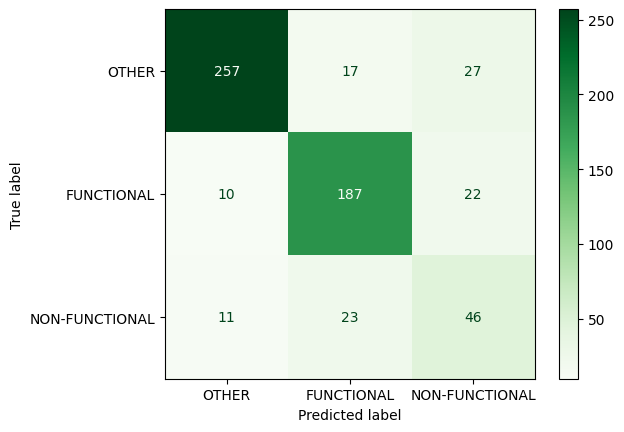

In [22]:
ConfusionMatrixDisplay.from_estimator(
    svm_pipe,
    X_test,
    y_test,
    display_labels=y_levels,
    cmap='Greens'
)

In [23]:
svm_opt_predictions = svm_pipe.predict(X_test)

print(metrics.classification_report(y_true=y_test, y_pred=svm_opt_predictions,
                                    target_names=y_levels))

                precision    recall  f1-score   support

         OTHER       0.92      0.85      0.89       301
    FUNCTIONAL       0.82      0.85      0.84       219
NON-FUNCTIONAL       0.48      0.57      0.53        80

      accuracy                           0.82       600
     macro avg       0.74      0.76      0.75       600
  weighted avg       0.83      0.82      0.82       600



In [24]:
bacc_svm_opt = metrics.balanced_accuracy_score(y_test, svm_opt_predictions)
print(f"Balanced accuracy: {bacc_svm_opt:0.4f}" )

Balanced accuracy: 0.7609


### UPOREDJIVANJE SVIH MODELA

na kolokvijumu ce biti dostupne sledece pomocne f-je

! pogledati napomene u primeru kolokvijuma

In [25]:
def get_model_metrics(y_true, y_pred, model_name):

    report = metrics.classification_report(y_true, y_pred, output_dict=True)

    b_acc = metrics.balanced_accuracy_score(y_true, y_pred)

    macro_avg = report['macro avg']
    weighted_avg = report['weighted avg']

    results = {
        'Model': model_name,
        'Macro Precision': macro_avg['precision'],
        'Macro Recall': macro_avg['recall'],
        'Macro F1-Score': macro_avg['f1-score'],
        'Weighted Precision': weighted_avg['precision'],
        'Weighted Recall': weighted_avg['recall'],
        'Weighted F1-Score': weighted_avg['f1-score'],
        'Balanced Accuracy': b_acc
    }

    return results

In [26]:
from sklearn.dummy import DummyClassifier

dummy_clf = DummyClassifier(strategy='stratified')

dummy_clf.fit(X_train, y_train)

dummy_pred = dummy_clf.predict(X_test)

In [27]:
model_predictions = {
    'W2V_LR': lr_predictions,
    'W2V_LinSVM': svm_predictions,
    'W2V_OptLinSVM': svm_opt_predictions,
    'DUMMY': dummy_pred
}

all_results = list()

for model_name, model_pred in model_predictions.items():
  model_res = get_model_metrics(y_test, model_pred, model_name)
  all_results.append(model_res)

all_results_df = pd.DataFrame(all_results)
all_results_df.set_index("Model", inplace=True)
all_results_df = all_results_df.apply(lambda x: round(x, 4))

print("Model Performance Comparison:")
print(all_results_df)

Model Performance Comparison:
               Macro Precision  Macro Recall  Macro F1-Score  \
Model                                                          
W2V_LR                  0.7402        0.7723          0.7472   
W2V_LinSVM              0.7296        0.7526          0.7372   
W2V_OptLinSVM           0.7442        0.7609          0.7507   
DUMMY                   0.3108        0.3119          0.3111   

               Weighted Precision  Weighted Recall  Weighted F1-Score  \
Model                                                                   
W2V_LR                     0.8268           0.7983             0.8081   
W2V_LinSVM                 0.8152           0.7967             0.8039   
W2V_OptLinSVM              0.8290           0.8167             0.8215   
DUMMY                      0.3894           0.3900             0.3895   

               Balanced Accuracy  
Model                             
W2V_LR                    0.7723  
W2V_LinSVM                0.7526  
W2V_Op